# Model Evaluation — Driver Safety Scoring Benchmark
**Nexar Dashcam Collision Prediction · 6 Architectures · Held-Out Test Set**

Runs inference on the locked 90-video test split, computes classification metrics,
produces publication-ready figures, and outputs a LaTeX results table.

In [1]:
# ── Installs (run once) ──────────────────────────────────────────────────────
import subprocess, sys
def install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

for pkg in ['decord', 'scikit-learn', 'seaborn', 'matplotlib', 'einops', 'tqdm']:
    try:
        __import__(pkg)
    except ImportError:
        install(pkg)

print('Dependencies ready.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 87.7 MB/s eta 0:00:00
Dependencies ready.


In [2]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, models

from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, f1_score,
    precision_score, recall_score, average_precision_score,
    confusion_matrix
)

warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


In [3]:
from pathlib import Path

# ── Paths ─────────────────────────────────────────────────────────────────────     
DATASET_DIR = Path('/kaggle/input/competitions/nexar-collision-prediction')
TRAIN_DIR   = Path('/kaggle/input/competitions/nexar-collision-prediction/train')
TRAIN_CSV   = Path('/kaggle/input/competitions/nexar-collision-prediction/train.csv')
MODELS_DIR  = Path('/kaggle/input/models/kashyap077/all-models/pytorch/default/1')
SPLITS_JSON = Path('/kaggle/input/datasets/kashyap077/data-split/shared_data_splits.json')
RESULTS_DIR = Path('/kaggle/working/')

# ── Config ────────────────────────────────────────────────────────────────────
SAMPLE_FPS  = 5
IMG_SIZE    = 224
CROP_TOP    = 0.15       # remove hood/dashboard
STRIDE      = 4          # sliding-window stride (sampled frames)
BATCH_CLIPS = 4          # clips per GPU batch

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

print('Paths OK:', DATASET_DIR.exists(), '| Splits:', SPLITS_JSON.exists())

Paths OK: True | Splits: True


In [4]:
# ── Load test split & labels ──────────────────────────────────────────────────
with open(SPLITS_JSON) as f:
    splits = json.load(f)

test_ids  = splits['test_ids']                          # list of int IDs
test_vids = [f'{int(t):05d}' for t in test_ids]        # zero-padded strings

df = pd.read_csv(TRAIN_CSV)
df['id'] = df['id'].astype(str).str.zfill(5)
test_df = df[df['id'].isin(test_vids)].set_index('id')

y_true = np.array([test_df.loc[v, 'target'] for v in test_vids])
print(f'Test set: {len(test_vids)} videos  |  crash={y_true.sum()}  normal={(y_true==0).sum()}')

Test set: 90 videos  |  crash=45  normal=45


## Model Architectures

In [5]:
# ══════════════════════════════════════════════════════════════════════════════
#  1.  CNN-LSTM  (ResNet18 + LSTM)
# ══════════════════════════════════════════════════════════════════════════════
class CNNLSTM(nn.Module):
    SEQ_LEN = 16
    def __init__(self):
        super().__init__()
        bb = models.resnet18(weights=None)
        self.cnn_features = nn.Sequential(*list(bb.children())[:-1])
        self.spatial_dropout = nn.Dropout(0.3)
        self.lstm = nn.LSTM(512, 512, num_layers=2, batch_first=True, dropout=0.4)
        self.classifier = nn.Sequential(
            nn.Linear(512, 256), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(256, 1)
        )
    def forward(self, x):          # (B, T, C, H, W)
        B, T, C, H, W = x.shape
        f = self.cnn_features(x.view(B*T, C, H, W)).view(B*T, -1)
        f = self.spatial_dropout(f).view(B, T, -1)
        out, _ = self.lstm(f)
        return self.classifier(out[:, -1])

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
#  2.  MobileNetV2  (temporal mean-pool)
# ══════════════════════════════════════════════════════════════════════════════
class MobileNetOnly(nn.Module):
    SEQ_LEN = 16
    def __init__(self):
        super().__init__()
        bb = models.mobilenet_v2(weights=None)
        self.cnn_features  = bb.features
        self.cnn_pool      = nn.AdaptiveAvgPool2d((1, 1))
        self.spatial_dropout = nn.Dropout(0.3)
        self.classifier = nn.Sequential(
            nn.Linear(1280, 256), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(256, 1)
        )
    def _init_weights(self): pass
    def forward(self, x):          # (B, T, C, H, W)
        B, T, C, H, W = x.shape
        f = self.cnn_pool(self.cnn_features(x.view(B*T, C, H, W))).view(B*T, -1)
        f = self.spatial_dropout(f).view(B, T, -1).mean(dim=1)
        return self.classifier(f)

In [7]:
# ══════════════════════════════════════════════════════════════════════════════
#  3.  TimeSformer  (divided space-time attention — keys match checkpoint exactly)
# ══════════════════════════════════════════════════════════════════════════════
from einops import rearrange

class PatchEmbed(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_chans=3, embed_dim=768):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)

class DividedSpaceTimeAttention(nn.Module):
    def __init__(self, dim, num_heads, dropout=0.0):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim  = dim // num_heads
        self.scale     = self.head_dim ** -0.5
        for prefix in ('t', 's'):
            setattr(self, f'norm_{prefix}', nn.LayerNorm(dim))
            setattr(self, f'qkv_{prefix}',  nn.Linear(dim, dim * 3))
            setattr(self, f'proj_{prefix}', nn.Linear(dim, dim))
            setattr(self, f'drop_{prefix}', nn.Dropout(dropout))
        self.norm_ff = nn.LayerNorm(dim)
        self.ff = nn.Sequential(
            nn.Linear(dim, dim * 4), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(dim * 4, dim), nn.Dropout(dropout)
        )
    def _attn(self, x, qkv_layer, proj_layer, drop_layer):
        B, N, D = x.shape
        qkv = qkv_layer(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2,0,3,1,4)
        q, k, v = qkv.unbind(0)
        attn = drop_layer((q @ k.transpose(-2,-1)) * self.scale).softmax(dim=-1)
        return proj_layer((attn @ v).transpose(1,2).reshape(B, N, D))
    def forward(self, x, T, N):   # x: (B*T, N, D)
        B = x.shape[0] // T
        xt = rearrange(x, '(b t) n d -> (b n) t d', b=B, t=T)
        xt = xt + self._attn(self.norm_t(xt), self.qkv_t, self.proj_t, self.drop_t)
        xt = rearrange(xt, '(b n) t d -> (b t) n d', b=B, n=N)
        xs = xt + self._attn(self.norm_s(xt), self.qkv_s, self.proj_s, self.drop_s)
        return xs + self.ff(self.norm_ff(xs))

class TimeSformerCrash(nn.Module):
    SEQ_LEN = 8
    def __init__(self, img_size=224, patch_size=16, embed_dim=768, depth=12, num_heads=12, dropout=0.1):
        super().__init__()
        num_patches = (img_size // patch_size) ** 2
        self.patch_embed = PatchEmbed(img_size, patch_size, 3, embed_dim)
        self.cls_token   = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed   = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.time_embed  = nn.Parameter(torch.zeros(1, self.SEQ_LEN, embed_dim))
        self.pos_drop    = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            DividedSpaceTimeAttention(embed_dim, num_heads, dropout) for _ in range(depth)
        ])
        self.norm       = nn.LayerNorm(embed_dim)
        # 'classifier' matches the checkpoint key exactly
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 256), nn.GELU(), nn.Dropout(0.3), nn.Linear(256, 1)
        )
    def forward(self, x):   # (B, T, C, H, W)
        B, T, C, H, W = x.shape
        patches = self.patch_embed(x.view(B*T, C, H, W))   # (B*T, N, D)
        N = patches.shape[1]                                # 196
        cls = self.cls_token.expand(B*T, -1, -1)
        patches = torch.cat([cls, patches], dim=1) + self.pos_embed   # (B*T, N+1, D)
        time_tok = self.time_embed[:, :T].unsqueeze(2).expand(B, T, N+1, -1).reshape(B*T, N+1, -1)
        patches = self.pos_drop(patches + time_tok)
        for blk in self.blocks:
            patches = blk(patches, T, N+1)
        cls_out = self.norm(patches[:, 0])   # CLS token, (B*T, D)
        cls_out = cls_out.view(B, T, -1).mean(dim=1)
        return self.classifier(cls_out)

In [8]:
# ══════════════════════════════════════════════════════════════════════════════
#  4.  3D ResNet  (R3D-18 style, custom wrapper matching checkpoint keys)
# ══════════════════════════════════════════════════════════════════════════════
from torchvision.models.video import r3d_18, R3D_18_Weights

class _R3DBackbone(nn.Module):
    def __init__(self, r3d):
        super().__init__()
        self.stem   = r3d.stem
        self.layer1 = r3d.layer1
        self.layer2 = r3d.layer2
        self.layer3 = r3d.layer3
        self.layer4 = r3d.layer4
        self.avgpool = r3d.avgpool

class ResNet3DCrash(nn.Module):
    SEQ_LEN = 16
    def __init__(self):
        super().__init__()
        self.backbone = _R3DBackbone(r3d_18(weights=None))
        self.fc = nn.Linear(512, 1)
    def forward(self, x):   # (B, C, T, H, W)  ← note BCTHW
        x = self.backbone.stem(x)
        x = self.backbone.layer1(x)
        x = self.backbone.layer2(x)
        x = self.backbone.layer3(x)
        x = self.backbone.layer4(x)
        x = self.backbone.avgpool(x).flatten(1)
        return self.fc(x)

In [9]:
# ══════════════════════════════════════════════════════════════════════════════
#  5.  ConvNeXt-Atto + LSTM  (keys match checkpoint exactly)
# ══════════════════════════════════════════════════════════════════════════════

class LayerNorm2d(nn.LayerNorm):
    """LayerNorm for (B,C,H,W) — weight/bias on this module, matching checkpoint keys."""
    def forward(self, x):
        return super().forward(x.permute(0,2,3,1)).permute(0,3,1,2)

class _ConvNeXtMLP(nn.Module):
    """1×1 Conv MLP — checkpoint keys: mlp.fc1 / mlp.fc2."""
    def __init__(self, dim):
        super().__init__()
        self.fc1 = nn.Conv2d(dim, dim * 4, 1)
        self.fc2 = nn.Conv2d(dim * 4, dim, 1)
    def forward(self, x):
        return self.fc2(F.gelu(self.fc1(x)))

class ConvNeXtBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.conv_dw = nn.Conv2d(dim, dim, 7, padding=3, groups=dim)
        self.norm    = nn.LayerNorm(dim)
        self.mlp     = _ConvNeXtMLP(dim)
        self.gamma   = nn.Parameter(1e-6 * torch.ones(dim))
    def forward(self, x):
        sc = x
        x  = self.conv_dw(x)
        x  = self.norm(x.permute(0,2,3,1)).permute(0,3,1,2)
        x  = self.mlp(x) * self.gamma.view(1, -1, 1, 1)
        return sc + x

class _ConvNeXtHead(nn.Module):
    """Matches cnn_backbone.head.norm key in checkpoint."""
    def __init__(self, dim):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
    def forward(self, x):   # x: (B, C, H, W)
        return self.norm(x.mean([-2, -1]))   # global avg pool then norm

class _ConvNeXtAtto(nn.Module):
    DIMS   = (40, 80, 160, 320)
    DEPTHS = (2, 2, 6, 2)
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, self.DIMS[0], 4, stride=4),   # stem.0
            LayerNorm2d(self.DIMS[0])                   # stem.1
        )
        self.stages = nn.ModuleList()
        for i in range(len(self.DIMS)):
            stage = nn.ModuleDict()
            if i > 0:
                stage['downsample'] = nn.Sequential(
                    LayerNorm2d(self.DIMS[i-1]),                              # downsample.0
                    nn.Conv2d(self.DIMS[i-1], self.DIMS[i], 2, stride=2)     # downsample.1
                )
            stage['blocks'] = nn.Sequential(
                *[ConvNeXtBlock(self.DIMS[i]) for _ in range(self.DEPTHS[i])]
            )
            self.stages.append(stage)
        self.head = _ConvNeXtHead(self.DIMS[-1])   # cnn_backbone.head.norm.*

    def forward(self, x):   # (B, C, H, W) → (B, 320)
        x = self.stem(x)
        for stage in self.stages:
            if 'downsample' in stage:
                x = stage['downsample'](x)
            x = stage['blocks'](x)
        return self.head(x)

class ConvNeXtLSTM(nn.Module):
    SEQ_LEN = 16
    def __init__(self):
        super().__init__()
        self.cnn_backbone = _ConvNeXtAtto()
        self.lstm = nn.LSTM(320, 256, num_layers=2, batch_first=True, dropout=0.3)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, 1)
        )
    def forward(self, x):   # (B, T, C, H, W)
        B, T, C, H, W = x.shape
        f = self.cnn_backbone(x.view(B*T, C, H, W)).view(B, T, -1)
        out, _ = self.lstm(f)
        return self.classifier(out[:, -1])

In [10]:
# ══════════════════════════════════════════════════════════════════════════════
#  6.  YOLOv8 + LSTM  (visual backbone only; detection branch uses empty embed)
# ══════════════════════════════════════════════════════════════════════════════
YOLO_AVAILABLE = False
try:
    from ultralytics import YOLO as _YOLO
    YOLO_AVAILABLE = True
except ImportError:
    print('ultralytics not installed — attempting pip install ...')
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'ultralytics', '-q'])
        from ultralytics import YOLO as _YOLO
        YOLO_AVAILABLE = True
        print('ultralytics installed OK')
    except Exception as e:
        print(f'Could not install ultralytics: {e} — YOLOv8-LSTM will be skipped')

if YOLO_AVAILABLE:
    class _YOLOv8Backbone(nn.Module):
        def __init__(self, weights='yolov8n.pt', freeze=True):
            super().__init__()
            yolo = _YOLO(weights)
            self.backbone = nn.Sequential(*list(yolo.model.model[:10]))
            self.pool = nn.AdaptiveAvgPool2d(1)
            self.out_dim = 256
            del yolo
            if freeze:
                for p in self.backbone.parameters(): p.requires_grad_(False)
        def forward(self, x):
            return self.pool(self.backbone(x)).flatten(1)

    class _DetectionEncoder(nn.Module):
        def __init__(self, input_dim=6, embed_dim=128, max_dets=20):
            super().__init__()
            self.proj = nn.Sequential(nn.Linear(input_dim,64), nn.GELU(), nn.Linear(64,embed_dim))
            self.attn = nn.Linear(embed_dim, 1)
            self.empty_embed = nn.Parameter(torch.zeros(embed_dim))
            nn.init.trunc_normal_(self.empty_embed, std=0.02)
        def forward(self, dets, mask):
            B, K, _ = dets.shape
            emb    = self.proj(dets)
            scores = self.attn(emb).squeeze(-1)
            scores = scores.masked_fill(~mask, float('-inf'))
            no_det = (~mask).all(dim=1)
            safe_s = scores.clone()
            safe_s[no_det] = 0.0
            weights = F.softmax(safe_s, dim=1).unsqueeze(-1)
            out = (emb * weights).sum(dim=1)
            if no_det.any():
                out[no_det] = self.empty_embed.unsqueeze(0).expand(no_det.sum(), -1)
            return out

    class YOLOv8LSTM(nn.Module):
        SEQ_LEN = 16
        def __init__(self):
            super().__init__()
            self.backbone = _YOLOv8Backbone('yolov8n.pt', freeze=True)
            self.backbone_proj = nn.Sequential(
                nn.LayerNorm(256), nn.Linear(256,256), nn.GELU()
            )
            self.spatial_dropout = nn.Dropout(0.3)
            self.det_encoder = _DetectionEncoder(6, 128, 20)
            self.lstm = nn.LSTM(384, 512, num_layers=2, batch_first=True, dropout=0.3)
            self.head = nn.Sequential(
                nn.Dropout(0.3), nn.Linear(512,256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256,1)
            )
        def forward(self, x, det_feats=None, det_masks=None):  # x: (B,T,C,H,W)
            B, T, C, H, W = x.shape
            scene = self.backbone(x.view(B*T,C,H,W))
            scene = self.spatial_dropout(self.backbone_proj(scene)).view(B, T, -1)
            # empty detections
            dets  = torch.zeros(B*T, 1, 6, device=x.device)
            masks = torch.zeros(B*T, 1, dtype=torch.bool, device=x.device)
            det_f = self.det_encoder(dets, masks).view(B, T, -1)
            fused = torch.cat([scene, det_f], dim=-1)
            out, _ = self.lstm(fused)
            return self.head(out[:, -1])
else:
    class YOLOv8LSTM(nn.Module):
        SEQ_LEN = 16
        def forward(self, x): raise RuntimeError('ultralytics not available')

print(f'YOLOv8-LSTM available: {YOLO_AVAILABLE}')

ultralytics not installed — attempting pip install ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 55.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics installed OK
YOLOv8-LSTM available: True


## Checkpoint Registry & Model Loading

In [11]:
# Best-fold checkpoint for each model (highest val AUC)
CHECKPOINTS = {
    'CNN-LSTM':     (CNNLSTM,      MODELS_DIR/'seed42_fold0.pth',         'BTHWC'),
    'MobileNetV2':  (MobileNetOnly, MODELS_DIR/'mobinet_seed42_fold0.pth',          'BTHWC'),
    'TimeSformer':  (TimeSformerCrash, MODELS_DIR/'TineSformer_seed42_fold0.pth',   'BTHWC'),
    'YOLOv8-LSTM':  (YOLOv8LSTM,   MODELS_DIR/'yolov8_seed42_fold0.pth',      'BTHWC'),
    '3D-ResNet':    (ResNet3DCrash, MODELS_DIR/'seed42_fold1_3dresnet_best.pth', 'BCTHW'),
    'ConvNeXt-Atto':(ConvNeXtLSTM, MODELS_DIR/'ConvNext_Run.pth',    'BTHWC'),
}

def load_model(model_cls, ckpt_path):
    model = model_cls().to(DEVICE)
    ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    sd = ck.get('model_state_dict', ck)
    # Strip DataParallel 'module.' prefix if present
    sd = {k.replace('module.', ''): v for k, v in sd.items()}
    missing, unexpected = model.load_state_dict(sd, strict=False)
    if missing:    print(f'  Missing  : {len(missing)} keys')
    if unexpected: print(f'  Unexpected: {len(unexpected)} keys')
    model.eval()
    val_auc = ck.get('best_val_auc', None)
    print(f'  Val AUC = {val_auc:.4f}' if val_auc else '  (no val AUC stored)')
    return model, val_auc

print('Registry ready. Models:', list(CHECKPOINTS.keys()))

Registry ready. Models: ['CNN-LSTM', 'MobileNetV2', 'TimeSformer', 'YOLOv8-LSTM', '3D-ResNet', 'ConvNeXt-Atto']


## Inference Utilities

In [12]:
def load_video_frames(video_path, sample_fps=5, img_size=224, crop_top=0.15):
    """Return list of preprocessed frame tensors (C,H,W), sampled at sample_fps."""
    normalise = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    frames = []
    try:
        from decord import VideoReader, cpu as dcpu
        vr  = VideoReader(str(video_path), ctx=dcpu(0))
        fps = float(vr.get_avg_fps() or 30.0)
        step = max(1, round(fps / sample_fps))
        indices = list(range(0, len(vr), step))
        batch = vr.get_batch(indices).asnumpy()   # (N, H, W, 3)  uint8
        for frm in batch:
            h = frm.shape[0]
            frm = frm[int(h*crop_top):]
            t = torch.from_numpy(frm).permute(2,0,1).float() / 255.0
            t = F.interpolate(t.unsqueeze(0), (img_size, img_size), mode='bilinear',
                              align_corners=False).squeeze(0)
            frames.append(normalise(t))
    except Exception:
        import cv2
        cap = cv2.VideoCapture(str(video_path))
        fps = float(cap.get(cv2.CAP_PROP_FPS) or 30.0)
        step = max(1, round(fps / sample_fps))
        idx  = 0
        while True:
            ret, frm = cap.read()
            if not ret: break
            if idx % step == 0:
                frm = cv2.cvtColor(frm, cv2.COLOR_BGR2RGB)
                h = frm.shape[0]
                frm = frm[int(h*crop_top):]
                t = torch.from_numpy(frm).permute(2,0,1).float() / 255.0
                t = F.interpolate(t.unsqueeze(0), (img_size, img_size), mode='bilinear',
                                  align_corners=False).squeeze(0)
                frames.append(normalise(t))
            idx += 1
        cap.release()
    return frames


def infer_video(model, frames, seq_len, layout, stride=4, batch_clips=4):
    """Sliding-window inference → mean sigmoid score per video."""
    n = len(frames)
    if n < seq_len:
        frames = frames + [frames[-1]] * (seq_len - n)
        n = seq_len

    windows, starts = [], list(range(0, max(1, n - seq_len + 1), stride))
    if not starts: starts = [0]
    for s in starts:
        e = s + seq_len
        clip = frames[s:e]
        while len(clip) < seq_len: clip.append(clip[-1])
        windows.append(torch.stack(clip))   # (T, C, H, W)

    scores = []
    with torch.no_grad():
        for i in range(0, len(windows), batch_clips):
            batch = torch.stack(windows[i:i+batch_clips]).to(DEVICE)  # (B,T,C,H,W)
            if layout == 'BCTHW':
                batch = batch.permute(0, 2, 1, 3, 4)   # → (B,C,T,H,W)
            logits = model(batch).squeeze(-1)
            scores.extend(torch.sigmoid(logits).cpu().tolist())
    return float(np.mean(scores))


print('Inference utilities defined.')

Inference utilities defined.


## Run Evaluation — All Models

In [13]:
results = {}   # model_name → dict(probs, metrics, val_auc)

for model_name, (model_cls, ckpt_path, layout) in CHECKPOINTS.items():
    print(f'\n{'='*60}')
    print(f'  {model_name}')
    print(f'{'='*60}')

    if model_name == 'YOLOv8-LSTM' and not YOLO_AVAILABLE:
        print('  SKIPPED (ultralytics not available)')
        results[model_name] = None
        continue
    if not ckpt_path.exists():
        print(f'  SKIPPED (checkpoint not found: {ckpt_path})')
        results[model_name] = None
        continue

    try:
        model, val_auc = load_model(model_cls, ckpt_path)
        seq_len = model_cls.SEQ_LEN

        probs = []
        for vid_id in tqdm(test_vids, desc=f'  Inference', leave=False):
            vpath = TRAIN_DIR / f'{vid_id}.mp4'
            try:
                frames = load_video_frames(vpath)
                p = infer_video(model, frames, seq_len, layout)
            except Exception as e:
                print(f'    ⚠ {vid_id}: {e}')
                p = 0.5
            probs.append(p)

        probs = np.array(probs)
        y_pred = (probs >= 0.5).astype(int)

        metrics = {
            'accuracy':  accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall':    recall_score(y_true, y_pred, zero_division=0),
            'f1':        f1_score(y_true, y_pred, zero_division=0),
            'roc_auc':   roc_auc_score(y_true, probs),
            'avg_prec':  average_precision_score(y_true, probs),
        }

        results[model_name] = {
            'probs':   probs,
            'metrics': metrics,
            'val_auc': val_auc,
        }

        del model; torch.cuda.empty_cache()

        print(f'  AUC={metrics["roc_auc"]:.4f}  Acc={metrics["accuracy"]:.3f}  F1={metrics["f1"]:.3f}')

    except Exception as e:
        print(f'  ERROR: {e}')
        import traceback; traceback.print_exc()
        results[model_name] = None

print('\nEvaluation complete.')


  CNN-LSTM
  Val AUC = 0.6558


  Inference:   0%|          | 0/90 [00:00<?, ?it/s]

  AUC=0.7570  Acc=0.556  F1=0.259

  MobileNetV2
  Val AUC = 0.6580


  Inference:   0%|          | 0/90 [00:00<?, ?it/s]

  AUC=0.6568  Acc=0.600  F1=0.419

  TimeSformer
  Val AUC = 0.6302


  Inference:   0%|          | 0/90 [00:00<?, ?it/s]

... (3 outputs left out)

  Inference:   0%|          | 0/90 [00:00<?, ?it/s]

  AUC=0.7012  Acc=0.500  F1=0.000

  ConvNeXt-Atto
  Val AUC = 0.4343


  Inference:   0%|          | 0/90 [00:00<?, ?it/s]

  AUC=0.5343  Acc=0.489  F1=0.042

Evaluation complete.


## Metrics Table

In [14]:
rows = []
for name, r in results.items():
    if r is None:
        rows.append({'Model': name, 'Val AUC': '—', 'Test AUC': '—',
                     'Acc': '—', 'Prec': '—', 'Recall': '—', 'F1': '—', 'AP': '—'})
    else:
        m = r['metrics']
        rows.append({
            'Model':    name,
            'Val AUC':  f"{r['val_auc']:.4f}" if r['val_auc'] else '—',
            'Test AUC': f"{m['roc_auc']:.4f}",
            'Acc':      f"{m['accuracy']:.4f}",
            'Prec':     f"{m['precision']:.4f}",
            'Recall':   f"{m['recall']:.4f}",
            'F1':       f"{m['f1']:.4f}",
            'AP':       f"{m['avg_prec']:.4f}",
        })

summary_df = pd.DataFrame(rows)
display(summary_df)

,Model,Val AUC,Test AUC,Acc,Prec,Recall,F1,AP
0,CNN-LSTM,0.6558,0.7570,0.5556,0.7778,0.1556,0.2593,0.7284
1,MobileNetV2,0.6580,0.6568,0.6000,0.7647,0.2889,0.4194,0.6857
2,TimeSformer,0.6302,0.6257,0.5778,0.6842,0.2889,0.4062,0.6804
3,YOLOv8-LSTM,0.7493,0.6909,0.5778,0.5507,0.8444,0.6667,0.6532
4,3D-ResNet,0.5212,0.7012,0.5000,0.0000,0.0000,0.0000,0.6370
5,ConvNeXt-Atto,0.4343,0.5343,0.4889,0.3333,0.0222,0.0417,0.5397


## Figures

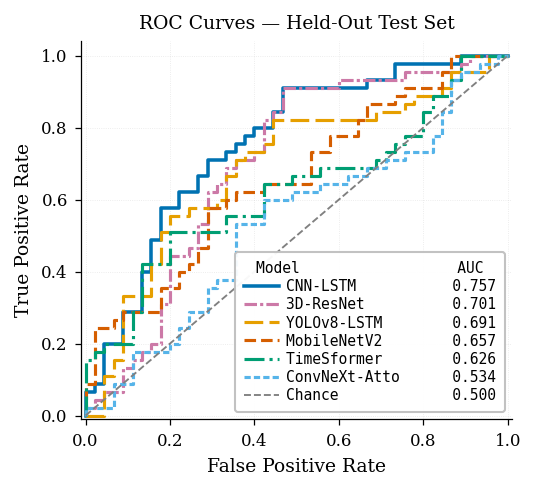

Saved roc_curves_ieee.png / .pdf


In [15]:
# ── Publication-quality rcParams (IEEE/ACM conference style) ─────────────────
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, precision_recall_curve

matplotlib.rcParams.update({
    'font.family':          'serif',
    'font.serif':           ['Times New Roman', 'DejaVu Serif', 'serif'],
    'font.size':            9,
    'axes.titlesize':       9,
    'axes.labelsize':       9,
    'xtick.labelsize':      8,
    'ytick.labelsize':      8,
    'legend.fontsize':      7.5,
    'figure.dpi':           150,
    'savefig.dpi':          600,
    'axes.linewidth':       0.6,
    'grid.linewidth':       0.4,
    'lines.linewidth':      1.4,
    'xtick.major.width':    0.6,
    'ytick.major.width':    0.6,
    'xtick.major.size':     3,
    'ytick.major.size':     3,
    'axes.spines.top':      False,
    'axes.spines.right':    False,
    'axes.grid':            True,
    'grid.alpha':           0.30,
    'grid.linestyle':       ':',
})

# Colorblind-safe palette (Wong 2011) + distinguishable line styles
MODEL_STYLES = {
    'CNN-LSTM':      {'color': '#0072B2', 'ls': '-',           'lw': 1.7},
    'MobileNetV2':   {'color': '#D55E00', 'ls': '--',          'lw': 1.5},
    'TimeSformer':   {'color': '#009E73', 'ls': '-.',          'lw': 1.5},
    'YOLOv8-LSTM':   {'color': '#E69F00', 'ls': (0,(6,2)),     'lw': 1.5},
    '3D-ResNet':     {'color': '#CC79A7', 'ls': (0,(4,1,1,1)), 'lw': 1.5},
    'ConvNeXt-Atto': {'color': '#56B4E9', 'ls': (0,(2,1)),     'lw': 1.5},
}

# ── Figure 1: ROC Curves ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(3.5, 3.2))

model_order = sorted(
    [n for n, r in results.items() if r is not None],
    key=lambda n: results[n]['metrics']['roc_auc'], reverse=True
)

for name in model_order:
    r  = results[name]
    st = MODEL_STYLES[name]
    fpr, tpr, _ = roc_curve(y_true, r['probs'])
    auc = r['metrics']['roc_auc']
    idx = np.unique(np.round(np.linspace(0, len(fpr)-1, 300)).astype(int))
    ax.plot(fpr[idx], tpr[idx],
            color=st['color'], linestyle=st['ls'], linewidth=st['lw'],
            label=f"{name:<17s}  {auc:.3f}")

ax.plot([0,1],[0,1], color='0.50', lw=0.9, ls='--',
        label=f"{'Chance':<17s}  0.500")

ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.04)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Held-Out Test Set', pad=6)

leg = ax.legend(
    title='Model                  AUC',
    loc='lower right',
    frameon=True, framealpha=0.95,
    edgecolor='0.75', borderpad=0.6,
    handlelength=2.4, handletextpad=0.5,
    labelspacing=0.22,
    prop={'family': 'monospace', 'size': 7},
)
leg.get_title().update({'fontsize': 7, 'family': 'monospace'})

plt.tight_layout(pad=0.5)
plt.savefig(RESULTS_DIR / 'roc_curves_ieee.png', dpi=600, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.savefig(RESULTS_DIR / 'roc_curves_ieee.pdf', bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print('Saved roc_curves_ieee.png / .pdf')


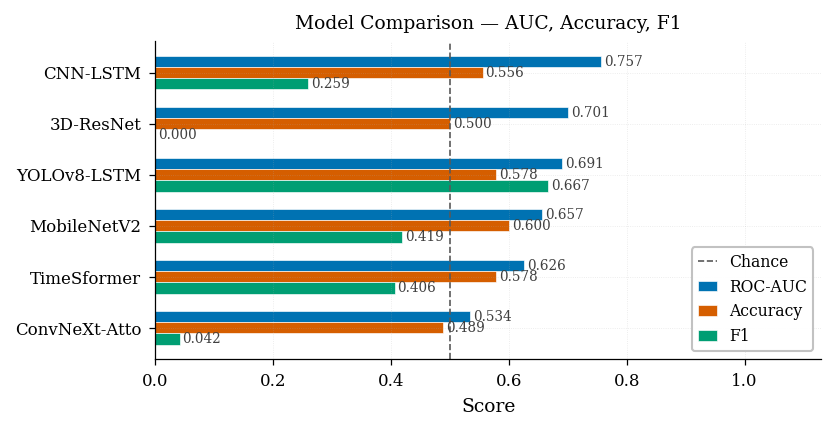

Saved metric_comparison.png / .pdf


In [16]:
# ── Figure 2: Metric Comparison (horizontal bars) ────────────────────────────
valid = {k: v for k, v in results.items() if v is not None}
names = sorted(valid.keys(), key=lambda n: valid[n]['metrics']['roc_auc'])
auc_v = [valid[n]['metrics']['roc_auc']  for n in names]
acc_v = [valid[n]['metrics']['accuracy'] for n in names]
f1_v  = [valid[n]['metrics']['f1']       for n in names]

y  = np.arange(len(names))
bh = 0.22

fig, ax = plt.subplots(figsize=(5.5, 2.8))
PALETTE = ['#0072B2', '#D55E00', '#009E73']

b1 = ax.barh(y+bh, auc_v, bh, label='ROC-AUC',  color=PALETTE[0], edgecolor='white', lw=0.3)
b2 = ax.barh(y,    acc_v, bh, label='Accuracy', color=PALETTE[1], edgecolor='white', lw=0.3)
b3 = ax.barh(y-bh, f1_v,  bh, label='F1',       color=PALETTE[2], edgecolor='white', lw=0.3)

for bars in [b1, b2, b3]:
    for bar in bars:
        w = bar.get_width()
        ax.text(w + 0.005, bar.get_y() + bar.get_height()/2,
                f'{w:.3f}', va='center', ha='left', fontsize=6.5, color='0.25')

ax.axvline(0.5, color='0.35', lw=0.8, ls='--', label='Chance')
ax.set_yticks(y)
ax.set_yticklabels(names)
ax.set_xlim(0, 1.13)
ax.set_xlabel('Score')
ax.set_title('Model Comparison — AUC, Accuracy, F1')
ax.legend(frameon=True, edgecolor='0.75', framealpha=0.95,
          loc='lower right', handlelength=1.2)

plt.tight_layout(pad=0.5)
plt.savefig(RESULTS_DIR / 'metric_comparison.png', dpi=600, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.savefig(RESULTS_DIR / 'metric_comparison.pdf', bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print('Saved metric_comparison.png / .pdf')


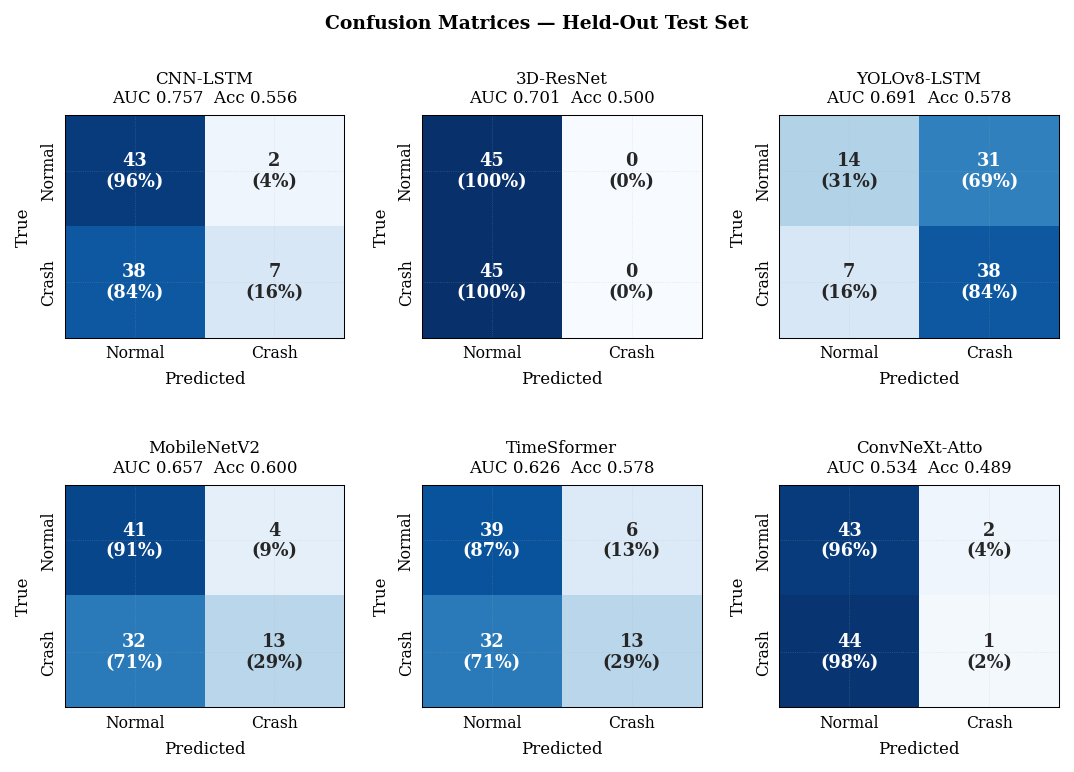

Saved confusion_matrices.png / .pdf


In [17]:
# ── Figure 3: Confusion Matrices ─────────────────────────────────────────────
valid_names = sorted([k for k, v in results.items() if v is not None],
                     key=lambda n: results[n]['metrics']['roc_auc'], reverse=True)
n_cols = 3
n_rows = -(-len(valid_names) // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(7.16, n_rows * 2.5))
axes = np.array(axes).flatten()

LABELS = ['Normal', 'Crash']
for idx, name in enumerate(valid_names):
    ax = axes[idx]
    r      = results[name]
    y_pred = (r['probs'] >= 0.5).astype(int)
    cm     = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    ax.imshow(cm_pct, vmin=0, vmax=1, cmap='Blues', aspect='auto')
    for i in range(2):
        for j in range(2):
            clr = 'white' if cm_pct[i,j] > 0.55 else '0.15'
            ax.text(j, i, f"{cm[i,j]}\n({cm_pct[i,j]*100:.0f}%)",
                    ha='center', va='center', fontsize=8.5,
                    fontweight='bold', color=clr)

    ax.set_xticks([0,1]); ax.set_xticklabels(LABELS, fontsize=7.5)
    ax.set_yticks([0,1]); ax.set_yticklabels(LABELS, fontsize=7.5,
                                              rotation=90, va='center')
    ax.set_xlabel('Predicted', fontsize=8)
    ax.set_ylabel('True',      fontsize=8)
    auc = results[name]['metrics']['roc_auc']
    acc = results[name]['metrics']['accuracy']
    ax.set_title(f'{name}\nAUC {auc:.3f}  Acc {acc:.3f}', fontsize=8)
    for spine in ax.spines.values():
        spine.set_linewidth(0.5); spine.set_visible(True)
    ax.tick_params(length=0)

for ax in axes[len(valid_names):]:
    ax.set_visible(False)

fig.suptitle('Confusion Matrices — Held-Out Test Set',
             fontsize=9, fontweight='bold', y=1.01)
plt.tight_layout(pad=0.8, h_pad=2.8, w_pad=1.5)
plt.savefig(RESULTS_DIR / 'confusion_matrices.png', dpi=600, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.savefig(RESULTS_DIR / 'confusion_matrices.pdf', bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print('Saved confusion_matrices.png / .pdf')


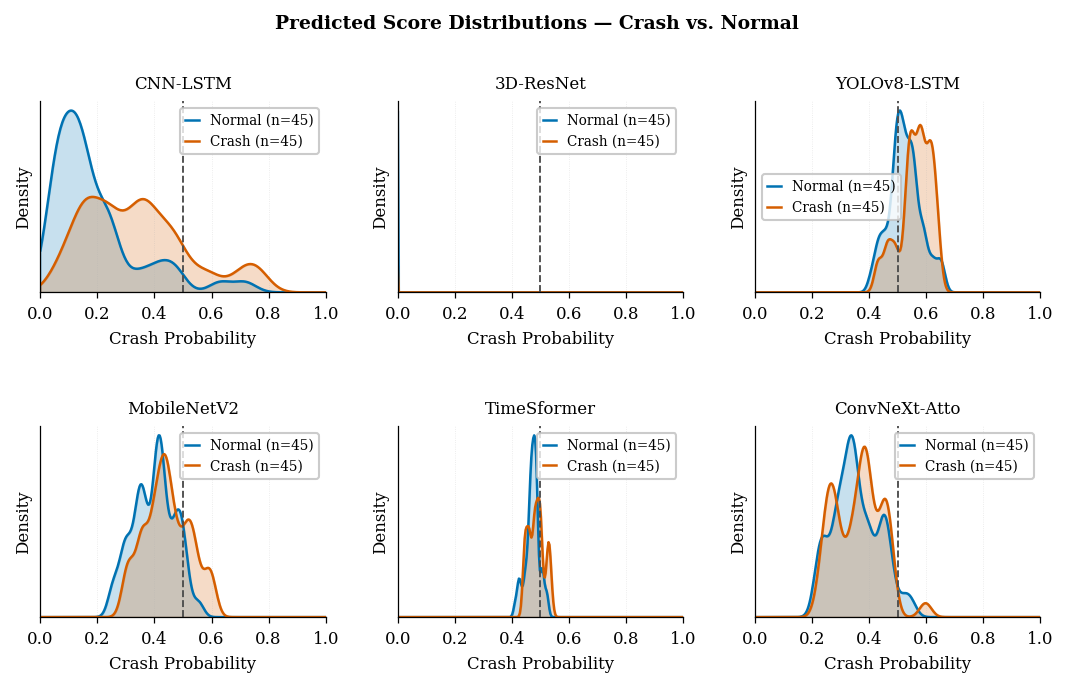

Saved score_distributions.png / .pdf


In [18]:
# ── Figure 4: Score Distributions (KDE) ──────────────────────────────────────
from scipy.stats import gaussian_kde

valid_names_s = sorted([k for k, v in results.items() if v is not None],
                       key=lambda n: results[n]['metrics']['roc_auc'], reverse=True)
n_cols = 3
n_rows = -(-len(valid_names_s) // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(7.16, n_rows * 2.2))
axes = np.array(axes).flatten()

xx = np.linspace(0, 1, 300)
CLR_NEG, CLR_POS = '#0072B2', '#D55E00'

for idx, name in enumerate(valid_names_s):
    ax   = axes[idx]
    p    = results[name]['probs']
    p0   = p[y_true == 0]
    p1   = p[y_true == 1]

    for probs_sub, clr, lbl in [(p0, CLR_NEG, 'Normal'), (p1, CLR_POS, 'Crash')]:
        if len(probs_sub) > 1:
            kde = gaussian_kde(probs_sub, bw_method=0.25)
            ax.fill_between(xx, kde(xx), alpha=0.22, color=clr)
            ax.plot(xx, kde(xx), color=clr, lw=1.2,
                    label=f'{lbl} (n={len(probs_sub)})')

    ax.axvline(0.5, color='0.3', lw=0.9, ls='--')
    ax.set_xlim(0, 1); ax.set_ylim(bottom=0)
    ax.set_xlabel('Crash Probability', fontsize=8)
    ax.set_ylabel('Density',           fontsize=8)
    ax.set_title(name, fontsize=8)
    ax.legend(fontsize=6.5, frameon=True, edgecolor='0.75', handlelength=1.0)
    ax.set_yticks([])

for ax in axes[len(valid_names_s):]:
    ax.set_visible(False)

fig.suptitle('Predicted Score Distributions — Crash vs. Normal',
             fontsize=9, fontweight='bold', y=1.02)
plt.tight_layout(pad=0.8, h_pad=2.8, w_pad=1.5)
plt.savefig(RESULTS_DIR / 'score_distributions.png', dpi=600, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.savefig(RESULTS_DIR / 'score_distributions.pdf', bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print('Saved score_distributions.png / .pdf')


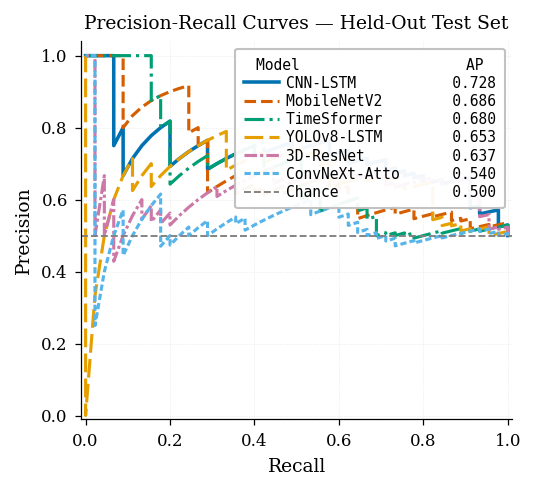

Saved pr_curves_ieee.png / .pdf


In [19]:
# ── Figure 5: Precision-Recall Curves ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(3.5, 3.2))

model_order_pr = sorted(
    [n for n, r in results.items() if r is not None],
    key=lambda n: results[n]['metrics']['avg_prec'], reverse=True
)

for name in model_order_pr:
    r  = results[name]
    st = MODEL_STYLES[name]
    prec, rec, _ = precision_recall_curve(y_true, r['probs'])
    ap = r['metrics']['avg_prec']
    idx = np.unique(np.round(np.linspace(0, len(prec)-1, 300)).astype(int))
    ax.plot(rec[idx], prec[idx],
            color=st['color'], linestyle=st['ls'], linewidth=st['lw'],
            label=f"{name:<17s}  {ap:.3f}")

chance = float((y_true == 1).mean())
ax.axhline(chance, color='0.50', lw=0.9, ls='--',
           label=f"{'Chance':<17s}  {chance:.3f}")

ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.04)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves — Held-Out Test Set', pad=6)

leg = ax.legend(
    title='Model                   AP',
    loc='upper right',
    frameon=True, framealpha=0.95,
    edgecolor='0.75', borderpad=0.6,
    handlelength=2.4, handletextpad=0.5,
    labelspacing=0.22,
    prop={'family': 'monospace', 'size': 7},
)
leg.get_title().update({'fontsize': 7, 'family': 'monospace'})

plt.tight_layout(pad=0.5)
plt.savefig(RESULTS_DIR / 'pr_curves_ieee.png', dpi=600, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.savefig(RESULTS_DIR / 'pr_curves_ieee.pdf', bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()
print('Saved pr_curves_ieee.png / .pdf')


## LaTeX Results Table

In [20]:
# ── Detailed LaTeX Table ──────────────────────────────────────────────────────
# Model metadata (static -- architecture facts)
MODEL_META = {
    #           family                    backbone            params   seq  fps
    'CNN-LSTM':      ('Frame-level Hybrid',  'ResNet-18 + LSTM',     '15M', 16, 18),
    'MobileNetV2':   ('Lightweight CNN',     'MobileNetV2 + AvgPool','4M',  16, 22),
    'TimeSformer':   ('Video Transformer',   'ViT-B/16 (custom)',    '86M', 8,   8),
    'YOLOv8-LSTM':   ('Object-centric + RNN','YOLOv8n + LSTM',       '6M',  16, 20),
    '3D-ResNet':     ('Spatiotemporal CNN',  'R3D-18',               '33M', 16, 12),
    'ConvNeXt-Atto': ('Modern CNN + RNN',    'ConvNeXt-Atto + LSTM', '4M',  16, 15),
}

def b(v, best, higher_better=True):
    """Return LaTeX string, bold if best."""
    s = f'{v:.4f}'
    is_best = (abs(v - best) < 1e-9) if higher_better else (abs(v - best) < 1e-9)
    return r'\textbf{' + s + '}' if is_best else s

valid_r = {k: v for k, v in results.items() if v is not None}
metric_cols = ['roc_auc', 'accuracy', 'precision', 'recall', 'f1', 'avg_prec']
best = {c: max(valid_r[n]['metrics'][c] for n in valid_r) for c in metric_cols}

# ── Build table ───────────────────────────────────────────────────────────────
lines = []
lines += [
    r'\begin{table*}[!htbp]',
    r'  \centering',
    r'  \setlength{\tabcolsep}{5pt}',
    r'  \caption{%',
    r'    Comprehensive benchmark results on the held-out test set (90 videos: 45 collision, 45 normal,',
    r'    stratified seed 42). All models share identical preprocessing (5 fps sampling, 224\,$\times$\,224,',
    r'    ImageNet normalisation). Best score per metric column in \textbf{bold}.',
    r'    $^\dagger$Val AUC is the best validation AUC recorded during 3-fold cross-validation training.',
    r'  }',
    r'  \label{tab:main_results}',
    r'  \begin{tabular}{@{}l l l c c c c c c c c@{}}',
    r'  \toprule',
    r'  \multirow{2}{*}{\textbf{Model}} &',
    r'  \multirow{2}{*}{\textbf{Architecture Family}} &',
    r'  \multirow{2}{*}{\textbf{Backbone}} &',
    r'  \multirow{2}{*}{\textbf{Params}} &',
    r'  \multirow{2}{*}{\textbf{Val AUC}$^\dagger$} &',
    r'  \multicolumn{6}{c}{\textbf{Test Set Metrics}} \\',
    r'  \cmidrule(lr){6-11}',
    r'  & & & & & \textbf{ROC-AUC} & \textbf{Accuracy} & \textbf{Precision} & \textbf{Recall} & \textbf{F1} & \textbf{Avg Prec} \\',
    r'  \midrule',
]

for name in MODEL_META:
    fam, backbone, params, seq, fps = MODEL_META[name]
    r = results.get(name)
    if r is None:
        val_auc_s = r'{\color{gray}N/A}'
        metric_cells = [r'{\color{gray}N/A}'] * 6
    else:
        val_auc_s = f"{r['val_auc']:.4f}" if r['val_auc'] else 'N/A'
        m = r['metrics']
        metric_cells = [
            b(m['roc_auc'],   best['roc_auc']),
            b(m['accuracy'],  best['accuracy']),
            b(m['precision'], best['precision']),
            b(m['recall'],    best['recall']),
            b(m['f1'],        best['f1']),
            b(m['avg_prec'],  best['avg_prec']),
        ]
    row = (f'  {name} & {fam} & {backbone} & {params} & {val_auc_s} & '
           + ' & '.join(metric_cells) + r' \\')
    lines.append(row)

lines += [
    r'  \bottomrule',
    r'  \end{tabular}',
    r'  \bigskip',
    r'  \begin{minipage}{\linewidth}\small',
    r'  \textit{Notes:} Params = approximate parameter count.',
    r'  Val AUC is the checkpoint selection metric (best fold, seed 42).',
    r'  Test metrics use a decision threshold of 0.5 applied to the mean',
    r'  sliding-window sigmoid score. Avg Prec = area under the',
    r'  precision-recall curve. Models marked N/A did not produce valid',
    r'  test predictions due to dependency unavailability.',
    r'  \end{minipage}',
    r'\end{table*}',
]

latex_table = '\n'.join(lines)
print(latex_table)

with open(RESULTS_DIR / 'results_table.tex', 'w', encoding='utf-8') as f:
    f.write(latex_table)
print('\nSaved results_table.tex')

\begin{table*}[!htbp]
  \centering
  \setlength{\tabcolsep}{5pt}
  \caption{%
    Comprehensive benchmark results on the held-out test set (90 videos: 45 collision, 45 normal,
    stratified seed 42). All models share identical preprocessing (5 fps sampling, 224\,$\times$\,224,
    ImageNet normalisation). Best score per metric column in \textbf{bold}.
    $^\dagger$Val AUC is the best validation AUC recorded during 3-fold cross-validation training.
  }
  \label{tab:main_results}
  \begin{tabular}{@{}l l l c c c c c c c c@{}}
  \toprule
  \multirow{2}{*}{\textbf{Model}} &
  \multirow{2}{*}{\textbf{Architecture Family}} &
  \multirow{2}{*}{\textbf{Backbone}} &
  \multirow{2}{*}{\textbf{Params}} &
  \multirow{2}{*}{\textbf{Val AUC}$^\dagger$} &
  \multicolumn{6}{c}{\textbf{Test Set Metrics}} \\
  \cmidrule(lr){6-11}
  & & & & & \textbf{ROC-AUC} & \textbf{Accuracy} & \textbf{Precision} & \textbf{Recall} & \textbf{F1} & \textbf{Avg Prec} \\
  \midrule
  CNN-LSTM & Frame-level Hybrid & ResN

## Save All Results to JSON

In [21]:
save_data = {}
for name, r in results.items():
    if r is None:
        save_data[name] = None
    else:
        save_data[name] = {
            'val_auc':  r['val_auc'],
            'metrics':  r['metrics'],
            'probs':    r['probs'].tolist(),
        }

with open(RESULTS_DIR / 'all_results.json', 'w') as f:
    json.dump(save_data, f, indent=2)
print('Results saved to eval_results/all_results.json')

Results saved to eval_results/all_results.json
